# 08 - PySpark implementations and benchmarking
The full benchmark (`src.pyspark_impl.spark_benchmark`) takes ~15-25 minutes on the target laptop; set `RUN_FULL_BENCHMARK = True` to rerun it. This notebook runs a live Spark demo of both techniques on the complete data and then loads the saved benchmark results.

**Note:** on Windows, run Jupyter from the space-free path `D:\ASBD_Hackathon` (Spark launch scripts break on paths with spaces).

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)
def show(f, w=900): display(Image(filename=str(ROOT / 'outputs' / 'plots' / f), width=w))

In [2]:
RUN_FULL_BENCHMARK = False
if RUN_FULL_BENCHMARK:
    from src.pyspark_impl import spark_benchmark
    spark_benchmark.run()

In [3]:
from src.pyspark_impl.spark_session import build_spark
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.clustering import KMeans
from pyspark.ml.functions import vector_to_array
from sklearn.metrics import roc_auc_score
import numpy as np, time
spark, startup = build_spark('notebook-demo'); print(f'Spark {spark.version} started in {startup:.1f}s')
dt = pd.read_csv('data/processed/dt_ml_matrix.csv').drop(columns='film_id')
feats = [c for c in dt.columns if c != 'acclaimed']
pos = dt.acclaimed.mean(); dt['w'] = np.where(dt.acclaimed == 1, 0.5 / pos, 0.5 / (1 - pos)); dt['label'] = dt.acclaimed.astype(float)
sdf = VectorAssembler(inputCols=feats, outputCol='features').transform(spark.createDataFrame(dt)).cache()
tr, te = sdf.randomSplit([0.75, 0.25], seed=42)
t0 = time.perf_counter(); m = DecisionTreeClassifier(weightCol='w', impurity='entropy', maxDepth=6, minInstancesPerNode=40, maxBins=256, seed=42).fit(tr)
out = m.transform(te).select(vector_to_array('probability').getItem(1).alias('p'), 'label').toPandas()
print(f'Spark DT fit+predict {time.perf_counter()-t0:.2f}s, test AUC {roc_auc_score(out.label, out.p):.3f}, nodes {m.numNodes}')
Z = pd.read_csv('data/processed/kmeans_director_matrix_z.csv').drop(columns='director')
zdf = VectorAssembler(inputCols=list(Z.columns), outputCol='features').transform(spark.createDataFrame(Z)).cache()
t0 = time.perf_counter(); km = KMeans(k=3, seed=42, maxIter=100).fit(zdf)
print(f'Spark K-Means fit {time.perf_counter()-t0:.2f}s, WCSS {km.summary.trainingCost:.1f}, sizes {km.summary.clusterSizes}')
spark.stop()

2026-11-21 13:59:40,450 | spark | INFO | Spark 4.0.1 session started in 12.93s (local[2])


Spark 4.0.1 started in 12.9s


Spark DT fit+predict 11.76s, test AUC 0.749, nodes 37


Spark K-Means fit 6.35s, WCSS 10784.3, sizes [192, 208, 282]


In [4]:
pd.read_csv('outputs/pyspark/performance_comparison_summary.csv')

,technique,workload,fraction,records,python_s,pyspark_s,pyspark_incl_convert_s,speedup,improvement_pct,python_quality,pyspark_quality
0,Decision tree,labelled films,0.10,280,0.031225,2.347620,5.672041,0.013301,-7418.327143,acc 0.686 / F1 0.500 / AUC 0.665,acc 0.686 / F1 0.500 / AUC 0.628
1,Decision tree,labelled films,0.25,700,0.012267,3.306616,4.898693,0.003710,-26855.158012,acc 0.566 / F1 0.493 / AUC 0.648,acc 0.566 / F1 0.493 / AUC 0.646
2,Decision tree,labelled films,0.50,1400,0.055840,3.060329,5.323836,0.018246,-5380.551513,acc 0.626 / F1 0.527 / AUC 0.704,acc 0.626 / F1 0.527 / AUC 0.728
3,Decision tree,labelled films,1.00,2801,0.026513,3.392180,5.040990,0.007816,-12694.498498,acc 0.653 / F1 0.573 / AUC 0.737,acc 0.653 / F1 0.573 / AUC 0.729
4,K-Means,directors,0.10,68,0.013096,3.360614,4.211984,0.003897,-25561.964486,WCSS 935 / sil 0.098,WCSS 930 / sil 0.069
5,K-Means,directors,0.25,170,0.018079,1.967691,2.407113,0.009188,-10783.786285,WCSS 2817 / sil 0.095,WCSS 2906 / sil 0.096
6,K-Means,directors,0.50,341,0.077426,4.048335,4.445018,0.019125,-5128.630967,WCSS 5259 / sil 0.111,WCSS 5333 / sil 0.110
7,K-Means,directors,1.00,682,0.023542,6.192486,6.917968,0.003802,-26203.546810,WCSS 10762 / sil 0.126,WCSS 11132 / sil 0.111
8,K-Means,films,0.10,1141,0.026384,6.906108,7.531297,0.003820,-26075.263163,WCSS 5842 / sil 0.137,WCSS 5876 / sil 0.122
9,K-Means,films,0.25,2852,0.067250,8.029515,8.931086,0.008375,-11839.852973,WCSS 15351 / sil 0.130,WCSS 15800 / sil 0.154


In [5]:
pd.read_csv('outputs/pyspark/benchmark_decision_tree.csv')

,workload,fraction,records,train,test,features,partitions,py_fit_s,py_predict_s,py_total_s,py_peak_mem_mb,spark_convert_s,spark_fit_s,spark_predict_s,spark_total_s,spark_total_incl_convert_s,spark_jvm_rss_mb,py_accuracy,spark_accuracy,py_f1,spark_f1,py_roc_auc,spark_roc_auc,py_leaves,spark_nodes,spark_depth,speedup,speedup_improvement_pct,speedup_incl_convert,speedup_incl_convert_improvement_pct
0,decision_tree_real,0.10,280,210,70,58,2,0.018615,0.012610,0.031225,0.084626,3.324421,1.569242,0.778378,2.347620,5.672041,426.369024,0.685714,0.685714,0.500000,0.500000,0.665125,0.628122,4,5,2,0.013301,-7418.327143,0.005505,-18064.888449
1,decision_tree_real,0.25,700,525,175,58,2,0.008600,0.003667,0.012267,0.157610,1.592077,2.905806,0.400810,3.306616,4.898693,308.793344,0.565714,0.565714,0.493333,0.493333,0.648082,0.645778,9,11,4,0.003710,-26855.158012,0.002504,-39833.590522
2,decision_tree_real,0.50,1400,1050,350,58,2,0.043418,0.012421,0.055840,0.300495,2.263507,2.823759,0.236570,3.060329,5.323836,764.887040,0.625714,0.625714,0.527076,0.527076,0.704119,0.727512,17,17,6,0.018246,-5380.551513,0.010489,-9434.124239
3,decision_tree_real,1.00,2801,2100,701,58,2,0.022886,0.003627,0.026513,0.595613,1.648810,3.115624,0.276556,3.392180,5.040990,475.488256,0.653352,0.653352,0.572935,0.572935,0.737453,0.729344,28,31,6,0.007816,-12694.498498,0.005259,-18913.419166


In [6]:
pd.read_csv('outputs/pyspark/benchmark_kmeans.csv')

,workload,fraction,records,features,k,partitions,py_fit_s,py_predict_s,py_total_s,py_peak_mem_mb,spark_convert_s,spark_fit_s,spark_predict_s,spark_total_s,spark_total_incl_convert_s,spark_jvm_rss_mb,py_wcss,spark_wcss,py_silhouette,spark_silhouette,ari_py_vs_spark,py_iterations,spark_iterations,speedup,speedup_improvement_pct,speedup_incl_convert,speedup_incl_convert_improvement_pct
0,kmeans_directors,0.10,68,19,3,2,0.011678,0.001418,0.013096,0.033988,0.851370,3.147188,0.213426,3.360614,4.211984,680.566784,934.558246,930.148618,0.098427,0.068701,0.260080,5,6,0.003897,-25561.964486,0.003109,-32063.106050
1,kmeans_directors,0.25,170,19,3,2,0.017296,0.000783,0.018079,0.080484,0.439422,1.859081,0.108610,1.967691,2.407113,819.933184,2817.067898,2906.469615,0.094792,0.096022,0.365930,14,6,0.009188,-10783.786285,0.007511,-13214.339804
2,kmeans_directors,0.50,341,19,3,2,0.068947,0.008479,0.077426,0.158444,0.396683,3.779594,0.268741,4.048335,4.445018,447.729664,5258.765428,5333.486786,0.110806,0.109564,0.302196,8,12,0.019125,-5128.630967,0.017419,-5640.966568
3,kmeans_directors,1.00,682,19,3,2,0.021783,0.001759,0.023542,0.275834,0.725482,6.048481,0.144006,6.192486,6.917968,769.593344,10761.653349,11132.457407,0.125778,0.110699,0.252133,7,26,0.003802,-26203.546810,0.003403,-29285.142996
4,kmeans_films,0.10,1141,51,6,2,0.024644,0.001740,0.026384,1.000012,0.625189,6.631878,0.274229,6.906108,7.531297,929.607680,5841.789269,5875.506594,0.137427,0.122189,0.555636,29,48,0.003820,-26075.263163,0.003503,-28444.830065
5,kmeans_films,0.25,2852,51,6,2,0.063730,0.003520,0.067250,2.396234,0.901571,7.492678,0.536837,8.029515,8.931086,754.110464,15351.160167,15800.285542,0.130123,0.154497,0.680983,22,23,0.008375,-11839.852973,0.007530,-13180.485125
6,kmeans_films,0.50,5704,51,6,2,0.229669,0.007117,0.236785,4.723420,2.289399,8.271000,0.464789,8.735790,11.025189,982.523904,30051.451091,30047.437206,0.128828,0.129254,0.955628,37,23,0.027105,-3589.326374,0.021477,-4556.192462
7,kmeans_films,1.00,11408,51,6,2,0.261248,0.004748,0.265995,9.378596,1.922158,14.397481,0.777486,15.174967,17.097126,1105.526784,61570.569727,63332.560895,0.125568,0.120911,0.725342,33,28,0.017529,-5604.973544,0.015558,-6327.601981


In [7]:
pd.read_csv('outputs/pyspark/benchmark_frequent_patterns.csv')

,workload,fraction,transactions,partitions,apriori_s,apriori_rules_s,apriori_total_s,apriori_peak_mem_mb,mlxtend_fpgrowth_s,spark_convert_s,spark_fpgrowth_total_s,spark_total_incl_convert_s,spark_jvm_rss_mb,apriori_itemsets,spark_itemsets,identical_itemsets_and_counts,apriori_rules_single_consequent,spark_rules,speedup,speedup_improvement_pct
0,frequent_patterns_real,0.10,1141,2,0.067060,0.055136,0.122196,0.264636,5.380836,0.481695,2.724181,3.205876,827.322368,314,314,True,205,205,0.044856,-2129.356900
1,frequent_patterns_real,0.25,2852,2,0.192310,0.025541,0.217852,0.416294,7.800195,0.353650,1.760657,2.114307,1106.812928,312,312,True,191,191,0.123733,-708.190759
2,frequent_patterns_real,0.50,5704,2,0.184427,0.004041,0.188468,0.683258,11.272917,0.410927,2.120203,2.531130,936.185856,307,307,True,157,157,0.088891,-1024.968403
3,frequent_patterns_real,1.00,11408,2,0.430655,0.005217,0.435872,1.218800,21.003755,0.439129,1.894166,2.333295,1020.882944,310,310,True,163,163,0.230113,-334.569200


In [8]:
pd.read_csv('outputs/pyspark/stress_test_replicated.csv')

,workload,fraction,records,train,test,features,partitions,py_fit_s,py_predict_s,py_total_s,py_peak_mem_mb,spark_convert_s,spark_fit_s,spark_predict_s,spark_total_s,spark_total_incl_convert_s,spark_jvm_rss_mb,py_accuracy,spark_accuracy,py_f1,...,k,py_wcss,spark_wcss,py_silhouette,spark_silhouette,ari_py_vs_spark,py_iterations,spark_iterations,transactions,apriori_s,apriori_rules_s,apriori_total_s,apriori_peak_mem_mb,mlxtend_fpgrowth_s,spark_fpgrowth_total_s,apriori_itemsets,spark_itemsets,identical_itemsets_and_counts,apriori_rules_single_consequent,spark_rules
0,decision_tree_replicated_x5,1.0,14005.0,10503.0,3502.0,58.0,2,0.079959,0.002757,0.082717,2.938360,1.965557,1.588550,0.422062,2.010612,3.976169,1133.703168,0.690463,0.690463,0.607246,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,kmeans_films_replicated_x5,1.0,57040.0,NaN,NaN,51.0,2,0.723895,0.018150,0.742046,46.613596,3.774254,17.746844,4.488835,22.235679,26.009933,1230.172160,NaN,NaN,NaN,...,6.0,3.054666e+05,3.054666e+05,0.141581,0.141581,0.999838,39.0,48.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,frequent_patterns_replicated_x5,1.0,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,0.916638,NaN,NaN,NaN,3.906019,977.776640,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,57040.0,1.119717,0.020312,1.140029,8.830156,54.028384,2.989381,310.0,310.0,True,163.0,163.0
3,decision_tree_replicated_x20,1.0,56020.0,42015.0,14005.0,58.0,2,0.281231,0.006460,0.287691,11.541090,4.261613,3.464791,0.322585,3.787376,8.048989,1356.218368,0.701321,0.701321,0.617537,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,kmeans_films_replicated_x20,1.0,228160.0,NaN,NaN,51.0,2,1.167293,0.030683,1.197976,186.247562,10.473689,34.020697,2.970112,36.990809,47.464498,1657.171968,NaN,NaN,NaN,...,6.0,1.227697e+06,1.227696e+06,0.140570,0.140559,0.998855,24.0,31.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,frequent_patterns_replicated_x20,1.0,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,1.932969,NaN,NaN,NaN,5.161140,2069.274624,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,228160.0,3.886097,0.006188,3.892286,38.681668,197.097485,3.228171,310.0,310.0,True,163.0,163.0


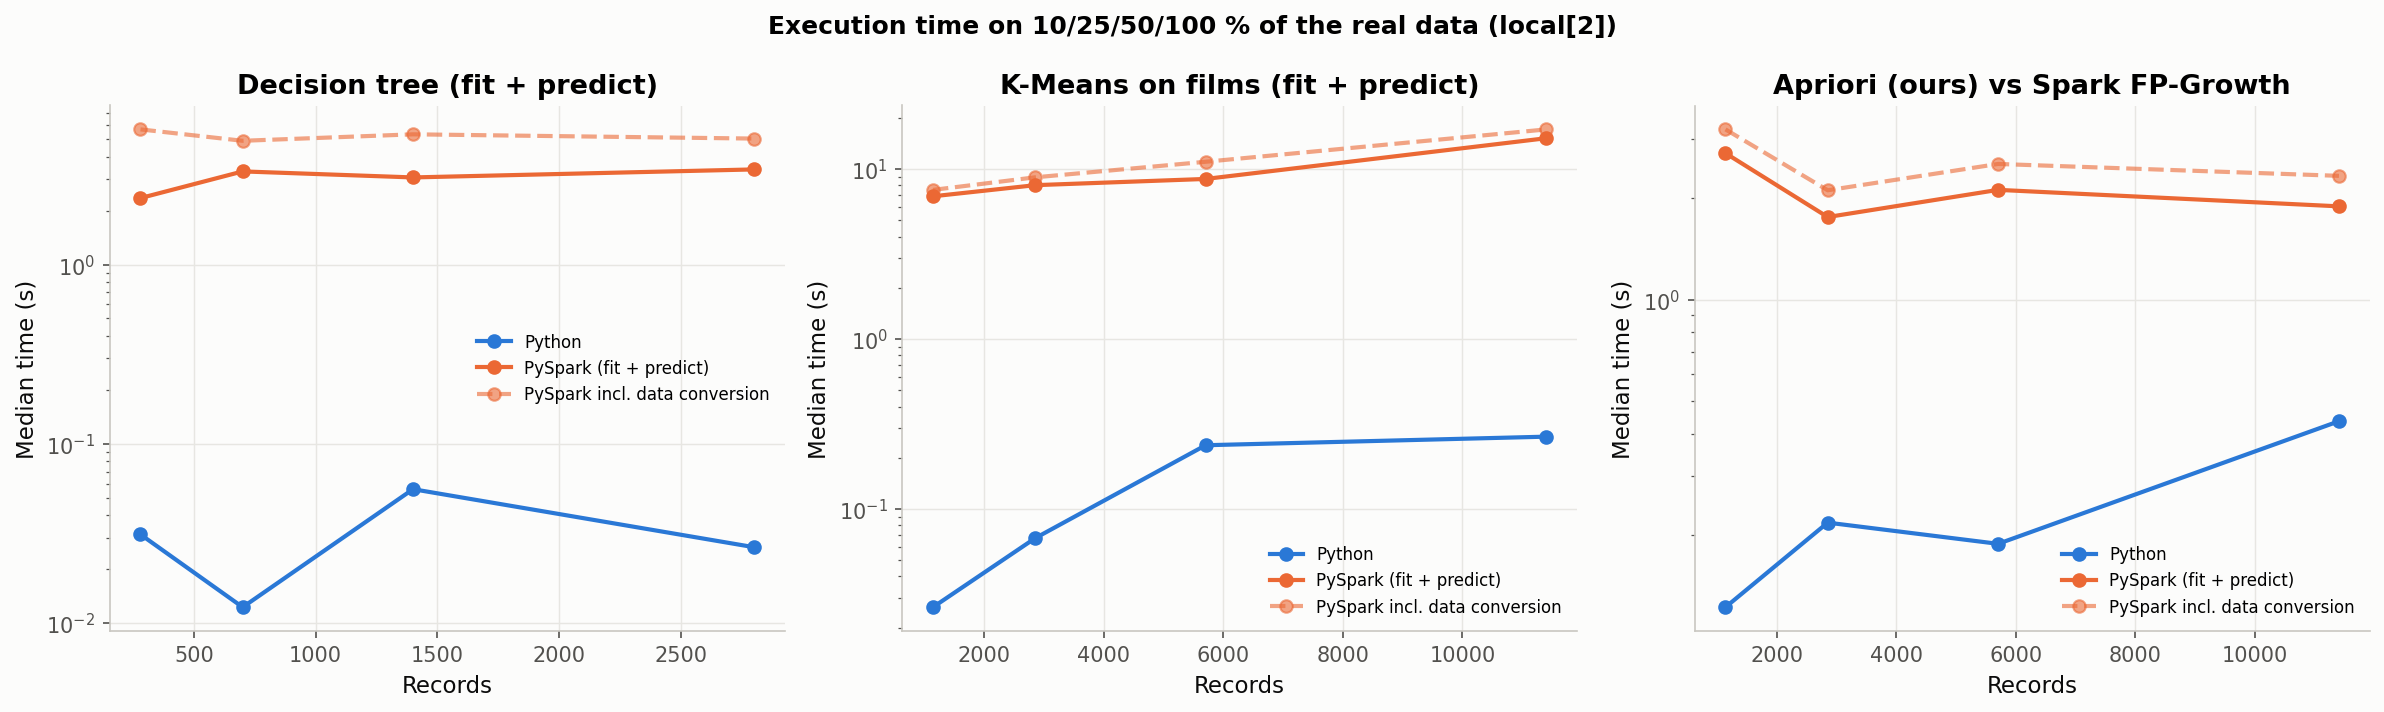

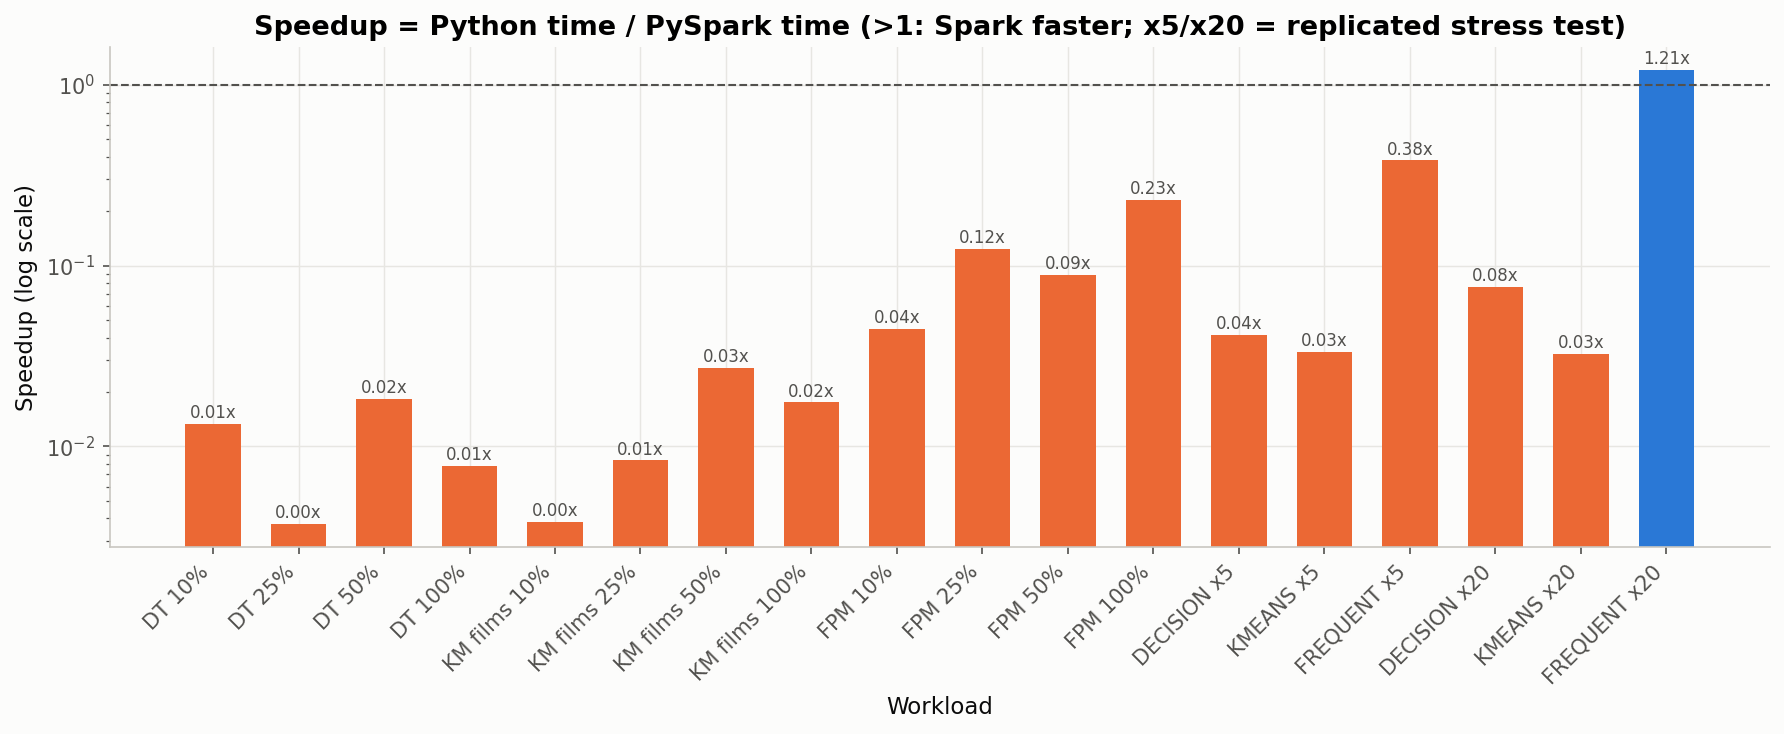

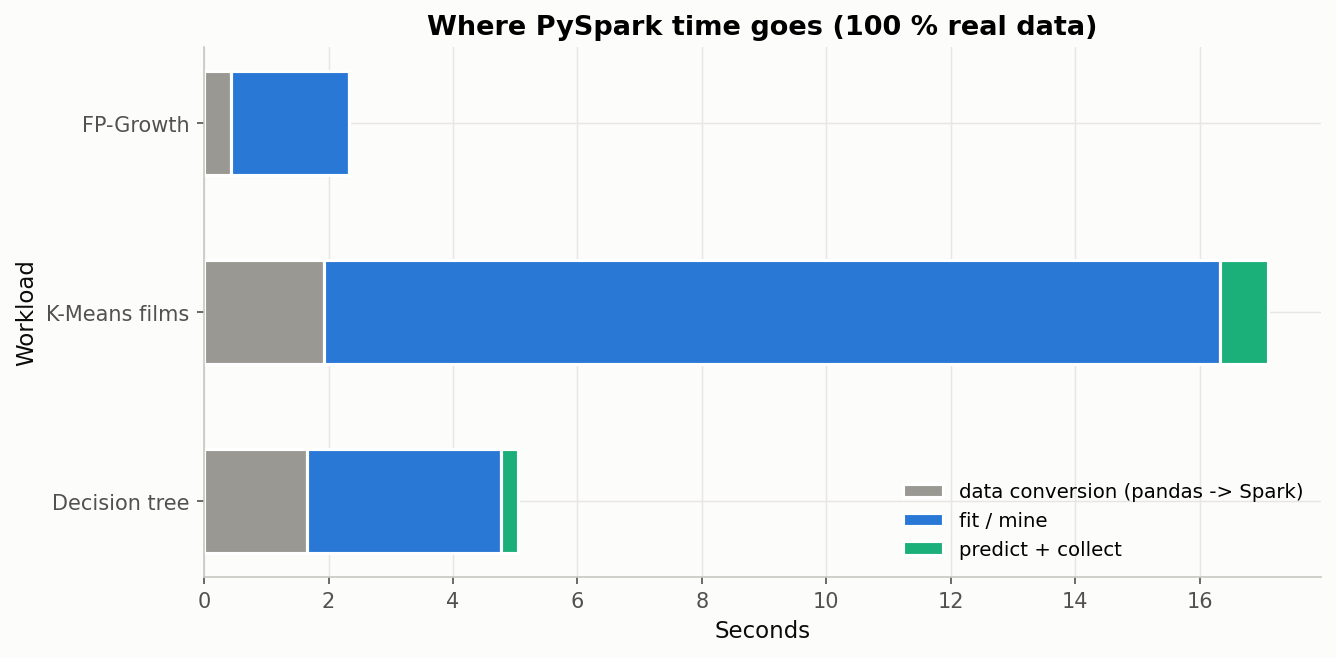

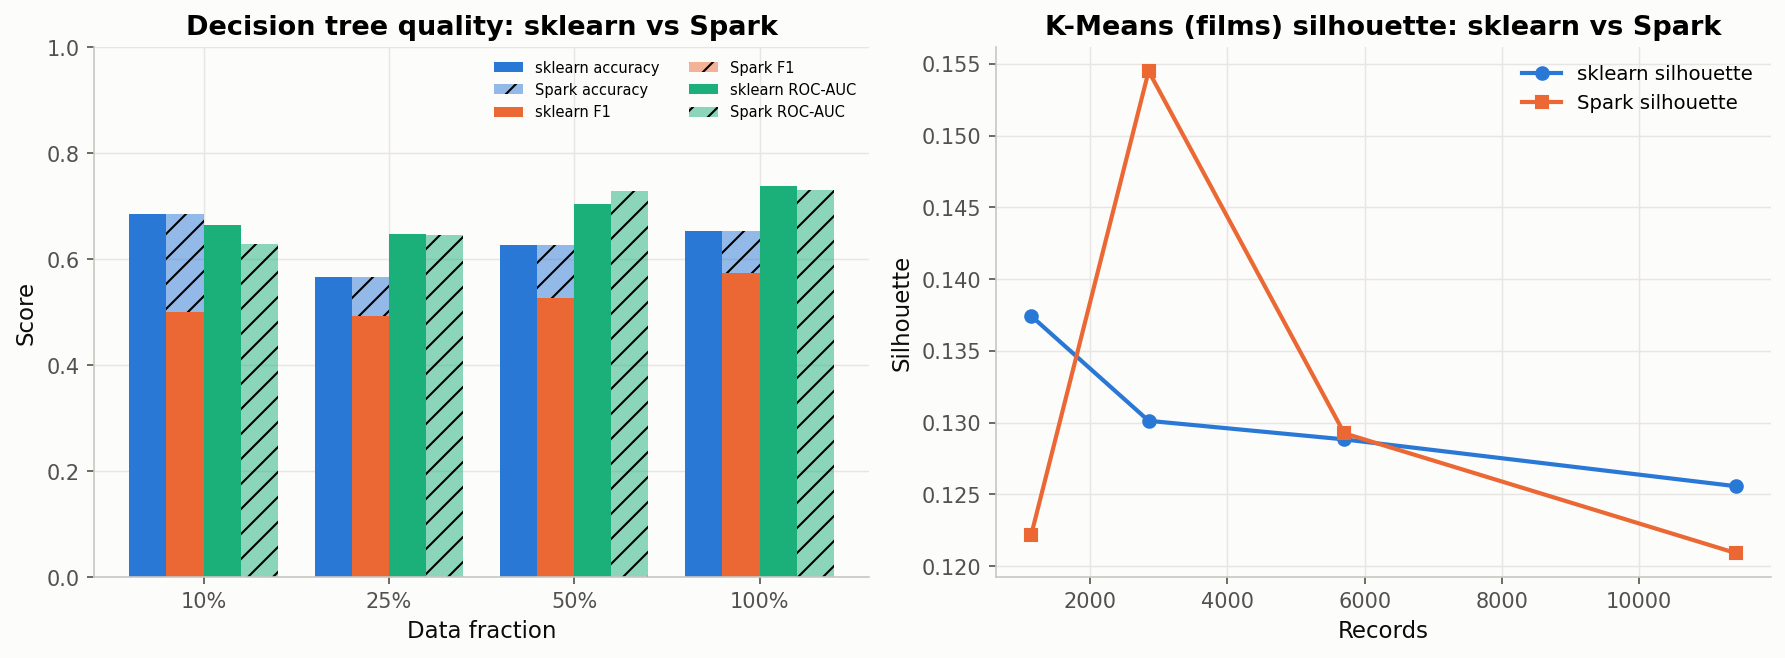

In [9]:
for f in ['38_pyspark_execution_time.png','39_pyspark_speedup.png','40_pyspark_time_breakdown.png','41_pyspark_quality_comparison.png']: show(f)